# Telco Customer Churn

The IBM Watson Telco Customer Churn dataset. Predicting whether a customer will leave in the next billing cycle. Classes are imbalanced (~27% churn) so I'm careful about how I evaluate — accuracy alone would be misleading.

Plan: light EDA, encode categoricals, baseline logreg, then random forest with class balancing, report precision/recall/F1 + the AUC.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

np.random.seed(2025)
DATA_DIR = Path("../../data/telco_churn")


In [2]:
df = pd.read_csv(DATA_DIR / "telco_churn.csv")
# TotalCharges in the real IBM file ships as strings with a few blanks — coerce
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
print(df.shape, "churn rate:", (df.Churn == "Yes").mean().round(3))
df.head()


(1500, 21) churn rate: 0.349


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,8732-JIDDH,Female,1,No,No,72,No,No phone service,Fiber optic,Yes,...,Yes,No,No,Yes,Two year,No,Electronic check,101.49,7277.50,No
1,5193-CDDHD,Male,0,No,No,13,Yes,Yes,DSL,No,...,No,Yes,No,No,Month-to-month,No,Electronic check,28.35,382.51,Yes
2,7053-ECEIA,Female,0,Yes,No,25,Yes,No,DSL,No,...,No,Yes,Yes,Yes,Two year,No,Bank transfer (automatic),110.32,2752.58,No
3,4016-DCDBJ,Female,1,Yes,Yes,15,No,No phone service,Fiber optic,No,...,Yes,Yes,No,Yes,One year,Yes,Bank transfer (automatic),98.59,1478.05,No
4,2099-HFJHF,Male,1,Yes,Yes,55,No,No phone service,Fiber optic,No,...,No,Yes,Yes,No,Month-to-month,No,Electronic check,58.95,3221.63,No


## Quick EDA

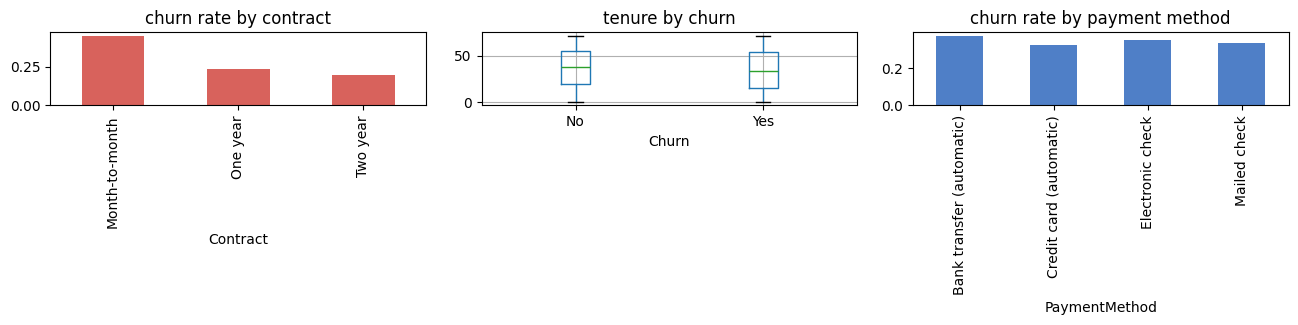

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
df.groupby("Contract")["Churn"].apply(lambda x: (x == "Yes").mean()).plot(kind="bar", ax=axes[0], color="#d8625c")
axes[0].set_title("churn rate by contract"); axes[0].set_ylabel("")
df.boxplot(column="tenure", by="Churn", ax=axes[1]); axes[1].set_title("tenure by churn")
df.groupby("PaymentMethod")["Churn"].apply(lambda x: (x == "Yes").mean()).plot(kind="bar", ax=axes[2], color="#4f7fc7")
axes[2].set_title("churn rate by payment method")
plt.suptitle(""); plt.tight_layout(); plt.show()


## Preprocessing

In [4]:
y = (df["Churn"] == "Yes").astype(int).values
drop_cols = ["customerID", "Churn"]
X = pd.get_dummies(df.drop(columns=drop_cols), drop_first=True).astype(float)
feature_names = X.columns.tolist()
X = X.values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=2025
)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)
print(f"train={X_train.shape}  test={X_test.shape}")


train=(1200, 30)  test=(300, 30)


## Modeling

In [5]:
models = {
    "LogReg (balanced)": (LogisticRegression(class_weight="balanced", max_iter=2000), X_train_s, X_test_s),
    "RF (balanced)":     (RandomForestClassifier(n_estimators=400, class_weight="balanced",
                                                 random_state=2025, n_jobs=-1), X_train, X_test),
}

for name, (clf, Xtr, Xte) in models.items():
    clf.fit(Xtr, y_train)
    proba = clf.predict_proba(Xte)[:, 1]
    pred = (proba >= 0.5).astype(int)
    print(f"--- {name} ---")
    print(f"AUC: {roc_auc_score(y_test, proba):.3f}")
    print(classification_report(y_test, pred, target_names=["stay", "churn"]))


--- LogReg (balanced) ---
AUC: 0.652
              precision    recall  f1-score   support

        stay       0.77      0.59      0.67       195
       churn       0.47      0.67      0.55       105

    accuracy                           0.62       300
   macro avg       0.62      0.63      0.61       300
weighted avg       0.66      0.62      0.63       300



--- RF (balanced) ---
AUC: 0.621
              precision    recall  f1-score   support

        stay       0.67      0.90      0.77       195
       churn       0.51      0.19      0.28       105

    accuracy                           0.65       300
   macro avg       0.59      0.55      0.52       300
weighted avg       0.62      0.65      0.60       300



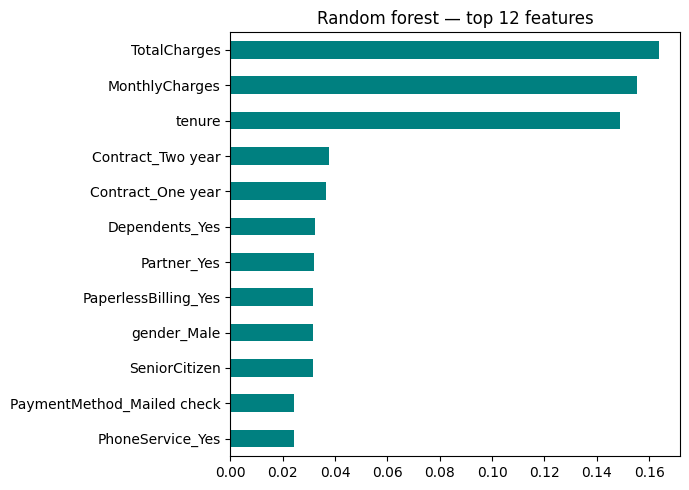

In [6]:
# top RF feature importances — useful as a sanity check
rf = models["RF (balanced)"][0]
imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False).head(12)
imp[::-1].plot(kind="barh", figsize=(7, 5), color="teal")
plt.title("Random forest — top 12 features")
plt.tight_layout(); plt.show()


## Notes

What the model usually leans on (and what you'd expect from telco churn):

- Contract type — month-to-month is by far the biggest signal.
- Tenure — newer customers leave faster.
- InternetService = Fiber optic — counter-intuitive but consistent across many published analyses; usually a cohort effect (fiber customers tend to be price-shopping).
- Payment method (electronic check) — proxy for some underlying customer segment.

A few things I deliberately did not do:
- SMOTE / oversampling. With 27% positives plus `class_weight="balanced"` it's not obviously needed.
- Gradient boosting. Would probably nudge AUC up a few points; left out to keep this short.
- Threshold tuning. For a real retention campaign you'd care more about the top-N highest-risk customers than 0.5 vs not 0.5.
